Leave-one-source-out (LOSO) BERT

In [1]:
import json
import pickle
import shutil
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import torch
from datasets import Dataset
from sklearn.metrics import classification_report, confusion_matrix, f1_score
from transformers import (
    AutoModelForSequenceClassification,
    AutoTokenizer,
    DataCollatorWithPadding,
    EarlyStoppingCallback,
    Trainer,
    TrainingArguments,
    set_seed,
)

SEED = 42
MODEL_CHECKPOINT = "bert-base-uncased"

SPLITS_ROOT = Path("../../data/splits")
ARTIFACTS_DIR = Path("../../data/artifacts")
WEIGHTS_ROOT = Path("../../weights")
RESULTS_DIR = Path("../../../results/bert/loso")
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

with open(ARTIFACTS_DIR / "label_encoder.pkl", "rb") as f:
    label_encoder = pickle.load(f)
LABEL_ORDER = list(label_encoder.classes_)
id2label = {i: c for i, c in enumerate(LABEL_ORDER)}
label2id = {c: i for i, c in enumerate(LABEL_ORDER)}

SOURCES = ["df1", "df5"]
print("Folds:", SOURCES)

C:\Users\oofuc\AppData\Local\Programs\Python\Python313\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Folds: ['df1', 'df5']


[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (521 > 512). Running this sequence through the model will result in indexing errors



Map:   0%|          | 0/254600 [00:00<?, ? examples/s]


Map:   1%|          | 2000/254600 [00:00<00:19, 12910.72 examples/s]


Map:   2%|▏         | 5000/254600 [00:00<00:15, 15989.75 examples/s]


Map:   3%|▎         | 8000/254600 [00:00<00:22, 11025.93 examples/s]


Map:   4%|▍         | 10000/254600 [00:00<00:19, 12755.08 examples/s]

... (138 outputs left out)


Writing model shards: 100%|██████████| 1/1 [00:00<00:00,  2.77it/s]


Writing model shards: 100%|██████████| 1/1 [00:00<00:00,  2.76it/s]

[transformers] There were missing keys in the checkpoint model loaded: ['bert.embeddings.LayerNorm.weight', 'bert.embeddings.LayerNorm.bias', 'bert.encoder.layer.0.attention.output.LayerNorm.weight', 'bert.encoder.layer.0.attention.output.LayerNorm.bias', 'bert.encoder.layer.0.output.LayerNorm.weight', 'bert.encoder.layer.0.output.LayerNorm.bias', 'bert.encoder.layer.1.attention.output.LayerNorm.weight', 'bert.encoder.layer.1.attention.output.LayerNorm.bias', 'bert.encoder.layer.1.output.LayerNorm.weight', 'bert.encoder.layer.1.output.LayerNorm.bias', 'bert.encoder.layer.2.attention.output.LayerNorm.weight', 'bert.encoder.layer.2.attention.output.LayerNorm.bias', 'bert.encoder.layer.2.output.LayerNorm.weight', 'bert.encoder.layer.2.output.LayerNorm.bias', 'bert.encoder.layer.3.attention.output.LayerNorm.weight', 'bert.encoder.layer.3.attention.output.LayerNorm.bias', 'bert.encoder.layer.3.output.LayerNorm.weight', 'bert.encoder.layer.3.output.LayerNorm.bias', 'bert.encoder.layer.4.atte

[transformers] There were unexpected keys in the checkpoint model loaded: ['bert.embeddings.LayerNorm.beta', 'bert.embeddings.LayerNorm.gamma', 'bert.encoder.layer.0.attention.output.LayerNorm.beta', 'bert.encoder.layer.0.attention.output.LayerNorm.gamma', 'bert.encoder.layer.0.output.LayerNorm.beta', 'bert.encoder.layer.0.output.LayerNorm.gamma', 'bert.encoder.layer.1.attention.output.LayerNorm.beta', 'bert.encoder.layer.1.attention.output.LayerNorm.gamma', 'bert.encoder.layer.1.output.LayerNorm.beta', 'bert.encoder.layer.1.output.LayerNorm.gamma', 'bert.encoder.layer.2.attention.output.LayerNorm.beta', 'bert.encoder.layer.2.attention.output.LayerNorm.gamma', 'bert.encoder.layer.2.output.LayerNorm.beta', 'bert.encoder.layer.2.output.LayerNorm.gamma', 'bert.encoder.layer.3.attention.output.LayerNorm.beta', 'bert.encoder.layer.3.attention.output.LayerNorm.gamma', 'bert.encoder.layer.3.output.LayerNorm.beta', 'bert.encoder.layer.3.output.LayerNorm.gamma', 'bert.encoder.layer.4.attention.

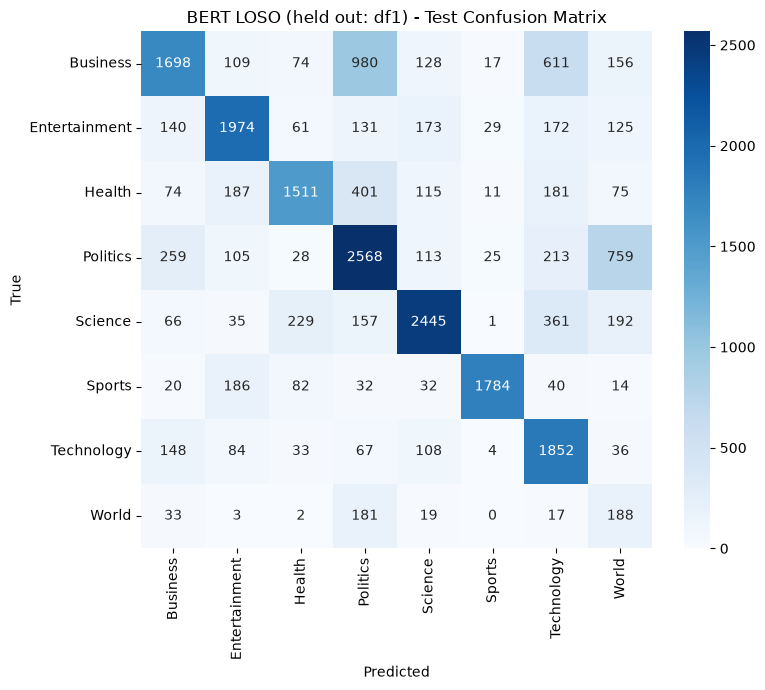


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]


Writing model shards: 100%|██████████| 1/1 [00:00<00:00,  1.67it/s]


Writing model shards: 100%|██████████| 1/1 [00:00<00:00,  1.66it/s]

loso_df1: macro_f1=0.6215 (n_test=21654, classes=8, train_time=8050.4s)


[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (1614 > 512). Running this sequence through the model will result in indexing errors



Map:   0%|          | 0/171082 [00:00<?, ? examples/s]

... (263 outputs left out)


Writing model shards: 100%|██████████| 1/1 [00:00<00:00,  2.88it/s]


Writing model shards: 100%|██████████| 1/1 [00:00<00:00,  2.87it/s]

[transformers] There were missing keys in the checkpoint model loaded: ['bert.embeddings.LayerNorm.weight', 'bert.embeddings.LayerNorm.bias', 'bert.encoder.layer.0.attention.output.LayerNorm.weight', 'bert.encoder.layer.0.attention.output.LayerNorm.bias', 'bert.encoder.layer.0.output.LayerNorm.weight', 'bert.encoder.layer.0.output.LayerNorm.bias', 'bert.encoder.layer.1.attention.output.LayerNorm.weight', 'bert.encoder.layer.1.attention.output.LayerNorm.bias', 'bert.encoder.layer.1.output.LayerNorm.weight', 'bert.encoder.layer.1.output.LayerNorm.bias', 'bert.encoder.layer.2.attention.output.LayerNorm.weight', 'bert.encoder.layer.2.attention.output.LayerNorm.bias', 'bert.encoder.layer.2.output.LayerNorm.weight', 'bert.encoder.layer.2.output.LayerNorm.bias', 'bert.encoder.layer.3.attention.output.LayerNorm.weight', 'bert.encoder.layer.3.attention.output.LayerNorm.bias', 'bert.encoder.layer.3.output.LayerNorm.weight', 'bert.encoder.layer.3.output.LayerNorm.bias', 'bert.encoder.layer.4.atte

[transformers] There were unexpected keys in the checkpoint model loaded: ['bert.embeddings.LayerNorm.beta', 'bert.embeddings.LayerNorm.gamma', 'bert.encoder.layer.0.attention.output.LayerNorm.beta', 'bert.encoder.layer.0.attention.output.LayerNorm.gamma', 'bert.encoder.layer.0.output.LayerNorm.beta', 'bert.encoder.layer.0.output.LayerNorm.gamma', 'bert.encoder.layer.1.attention.output.LayerNorm.beta', 'bert.encoder.layer.1.attention.output.LayerNorm.gamma', 'bert.encoder.layer.1.output.LayerNorm.beta', 'bert.encoder.layer.1.output.LayerNorm.gamma', 'bert.encoder.layer.2.attention.output.LayerNorm.beta', 'bert.encoder.layer.2.attention.output.LayerNorm.gamma', 'bert.encoder.layer.2.output.LayerNorm.beta', 'bert.encoder.layer.2.output.LayerNorm.gamma', 'bert.encoder.layer.3.attention.output.LayerNorm.beta', 'bert.encoder.layer.3.attention.output.LayerNorm.gamma', 'bert.encoder.layer.3.output.LayerNorm.beta', 'bert.encoder.layer.3.output.LayerNorm.gamma', 'bert.encoder.layer.4.attention.

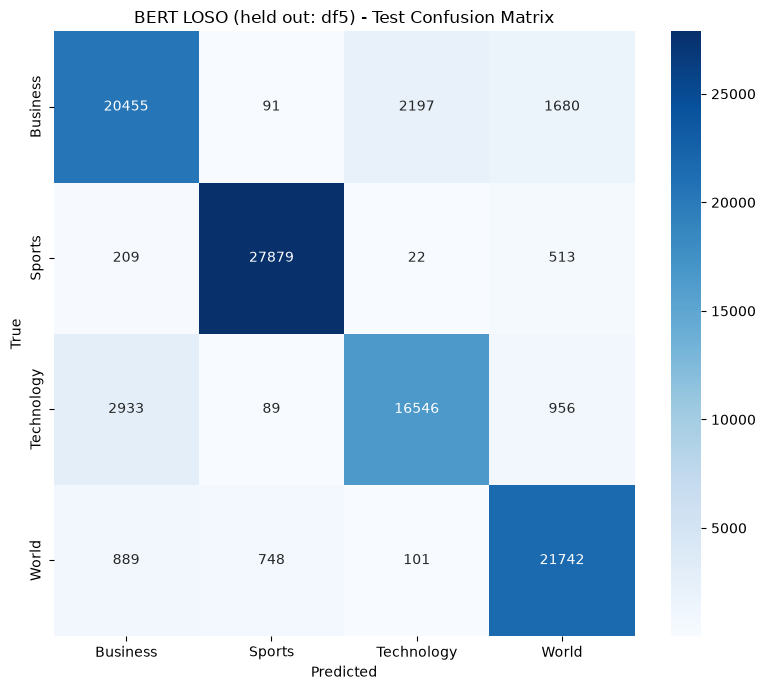


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]


Writing model shards: 100%|██████████| 1/1 [00:00<00:00,  3.77it/s]


Writing model shards: 100%|██████████| 1/1 [00:00<00:00,  3.75it/s]

loso_df5: macro_f1=0.7924 (n_test=119911, classes=4, train_time=19123.1s)


,held_out_source,n_train,n_test,n_classes_present,macro_f1,train_time_sec
0,df1,254600,21654,8,0.621535,8050.410635
1,df5,171082,119911,4,0.792412,19123.066128


In [2]:
loso_results = []

for held_out in SOURCES:
    set_seed(SEED)

    fold_dir = SPLITS_ROOT / f"loso_{held_out}"
    train_df = pd.read_csv(fold_dir / "train.csv")
    val_df = pd.read_csv(fold_dir / "val.csv")
    test_df = pd.read_csv(fold_dir / "test.csv")

    train_df["label"] = label_encoder.transform(train_df["category"])
    val_df["label"] = label_encoder.transform(val_df["category"])
    test_df["label"] = label_encoder.transform(test_df["category"])
    present_classes = np.unique(test_df["label"])
    present_class_names = label_encoder.inverse_transform(present_classes).tolist()

    tokenizer = AutoTokenizer.from_pretrained(MODEL_CHECKPOINT)

    SAMPLE_N = 20000
    sample_lengths = (
        train_df["text"]
        .sample(n=min(SAMPLE_N, len(train_df)), random_state=SEED)
        .apply(lambda t: len(tokenizer.encode(t, add_special_tokens=True)))
    )
    p95_len = int(np.percentile(sample_lengths, 95))
    max_length = int(np.clip(p95_len, 1, 512))
    max_length = min(((max_length + 7) // 8) * 8, 512)

    train_ds = Dataset.from_pandas(train_df[["text", "label"]].reset_index(drop=True))
    val_ds = Dataset.from_pandas(val_df[["text", "label"]].reset_index(drop=True))
    test_ds = Dataset.from_pandas(test_df[["text", "label"]].reset_index(drop=True))

    def tokenize_fn(batch, max_length=max_length):
        return tokenizer(batch["text"], truncation=True, max_length=max_length, padding=False)

    train_ds = train_ds.map(tokenize_fn, batched=True, remove_columns=["text"])
    val_ds = val_ds.map(tokenize_fn, batched=True, remove_columns=["text"])
    test_ds = test_ds.map(tokenize_fn, batched=True, remove_columns=["text"])

    data_collator = DataCollatorWithPadding(tokenizer=tokenizer)
    model = AutoModelForSequenceClassification.from_pretrained(
        MODEL_CHECKPOINT, num_labels=len(LABEL_ORDER), id2label=id2label, label2id=label2id,
    )

    def compute_metrics(eval_pred):
        logits, labels = eval_pred
        preds = np.argmax(logits, axis=-1)
        report = classification_report(
            labels, preds, labels=present_classes, target_names=present_class_names,
            output_dict=True, zero_division=0,
        )
        return {
            "macro_f1": report["macro avg"]["f1-score"],
        }

    fold_weights_dir = WEIGHTS_ROOT / f"loso_{held_out}" / "bert"
    fold_weights_dir.mkdir(parents=True, exist_ok=True)

    training_args = TrainingArguments(
        output_dir=str(fold_weights_dir),
        per_device_train_batch_size=16,
        per_device_eval_batch_size=32,
        num_train_epochs=3,
        learning_rate=2e-5,
        weight_decay=0.01,
        warmup_ratio=0.1,
        eval_strategy="epoch",
        save_strategy="epoch",
        save_total_limit=2,
        load_best_model_at_end=True,
        metric_for_best_model="macro_f1",
        greater_is_better=True,
        logging_steps=100,
        fp16=torch.cuda.is_available(),
        seed=SEED,
        data_seed=SEED,
        report_to="none",
    )

    trainer = Trainer(
        model=model,
        args=training_args,
        train_dataset=train_ds,
        eval_dataset=val_ds,
        data_collator=data_collator,
        compute_metrics=compute_metrics,
        callbacks=[EarlyStoppingCallback(early_stopping_patience=1)],
    )

    start_time = time.time()
    trainer.train()
    train_time_sec = time.time() - start_time

    inf_start = time.time()
    test_output = trainer.predict(test_ds)
    inf_time_sec = time.time() - inf_start
    y_pred = np.argmax(test_output.predictions, axis=-1)
    y_test = np.array(test_ds["label"])

    macro_f1 = f1_score(y_test, y_pred, labels=present_classes, average="macro", zero_division=0)
    report_dict = classification_report(
        y_test, y_pred, labels=present_classes, target_names=present_class_names,
        output_dict=True, zero_division=0,
    )

    cm = confusion_matrix(y_test, y_pred, labels=present_classes)
    plt.figure(figsize=(8, 7))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=present_class_names, yticklabels=present_class_names)
    plt.xlabel("Predicted")
    plt.ylabel("True")
    plt.title(f"BERT LOSO (held out: {held_out}) - Test Confusion Matrix")
    plt.tight_layout()
    plt.savefig(RESULTS_DIR / f"{held_out}_confusion_matrix.png", dpi=150)
    plt.show()
    plt.close()

    trainer.save_model(str(fold_weights_dir))
    tokenizer.save_pretrained(str(fold_weights_dir))

    metrics = {
        "model_family": "bert",
        "model_name": f"{MODEL_CHECKPOINT}-loso",
        "run_timestamp": pd.Timestamp.now("UTC").isoformat(),
        "label_order": LABEL_ORDER,
        "loso_held_out_source": held_out,
        "loso_classes_present": present_class_names,
        "config": {
            "max_length": max_length,
            "batch_size": training_args.per_device_train_batch_size,
            "epochs_planned": training_args.num_train_epochs,
            "epochs_trained": trainer.state.epoch,
            "learning_rate": training_args.learning_rate,
        },
        "train": {
            "n_train": len(train_df),
            "n_val": len(val_df),
            "train_time_sec": train_time_sec,
            "epochs_trained": trainer.state.epoch,
            "history": {"log_history": trainer.state.log_history},
        },
        "test": {
            "n_test": len(test_df),
            "n_classes_present": len(present_classes),
            "macro_f1": macro_f1,
            "per_class": {name: report_dict[name] for name in present_class_names},
            "confusion_matrix": cm.tolist(),
            "inf_time_sec": inf_time_sec,
            "inference_time_ms_per_sample": inf_time_sec / len(test_df) * 1000,
        },
        "environment": {
            "framework": "pytorch+transformers",
            "framework_version": torch.__version__,
            "device": "GPU" if torch.cuda.is_available() else "CPU",
            "seed": SEED,
        },
    }

    with open(RESULTS_DIR / f"{held_out}_metrics.json", "w", encoding="utf-8") as f:
        json.dump(metrics, f, indent=2)

    for sub in fold_weights_dir.glob("checkpoint-*"):
        if sub.is_dir():
            shutil.rmtree(sub)

    loso_results.append({
        "held_out_source": held_out,
        "n_train": len(train_df),
        "n_test": len(test_df),
        "n_classes_present": len(present_classes),
        "macro_f1": macro_f1,
        "train_time_sec": train_time_sec,
    })
    print(f"loso_{held_out}: macro_f1={macro_f1:.4f} (n_test={len(test_df)}, classes={len(present_classes)}, train_time={train_time_sec:.1f}s)")

loso_results_df = pd.DataFrame(loso_results)
loso_results_df

In [3]:
loso_results_df.to_csv(RESULTS_DIR / "bert_loso_summary.csv", index=False, encoding="utf-8")
print("Wrote:", (RESULTS_DIR / "bert_loso_summary.csv").resolve())
print("\nIn-distribution BERT_a test accuracy for comparison: 0.9018 (see results/bert/BERT_a_metrics.json)")
print("Mean LOSO macro_f1:", loso_results_df["macro_f1"].mean())

Wrote: D:\UoL\Sem2\mnu2\results\bert\loso\bert_loso_summary.csv

In-distribution BERT_a test accuracy for comparison: 0.9018 (see results/bert/BERT_a_metrics.json)
Mean LOSO macro_f1: 0.7069735943304913
